### Analysising Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os
import json
import time


In [10]:
df1 = pd.read_csv('prices_round_2_day_0.csv')
df2 = pd.read_csv('prices_round_2_day_-1.csv')
df3 = pd.read_csv('prices_round_2_day_1.csv')
os_df1 = df1[df1['product']=='ASH_COATED_OSMIUM']
os_df2 = df2[df2['product']=='ASH_COATED_OSMIUM']
os_df3 = df3[df3['product']=='ASH_COATED_OSMIUM']
os_df = pd.concat([os_df1,os_df2,os_df3],axis=0)
os_df.reset_index(inplace=True)

pr_df1 = df1[df1['product']=='INTARIAN_PEPPER_ROOT']
pr_df2 = df2[df2['product']=='INTARIAN_PEPPER_ROOT']
pr_df3 = df3[df3['product']=='INTARIAN_PEPPER_ROOT']
pr_df = pd.concat([pr_df1,pr_df2,pr_df3],axis=0)
pr_df.reset_index(inplace=True)


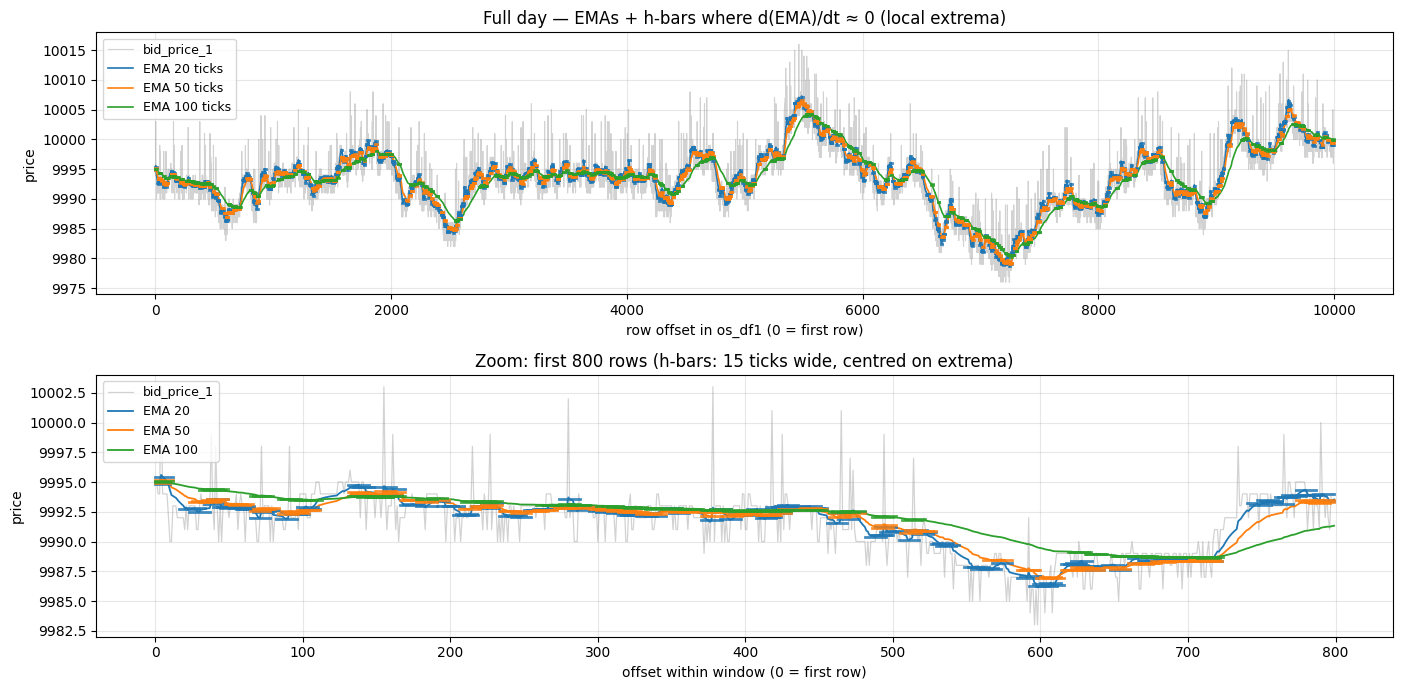

In [ ]:
# Tick-based EMAs: span = number of ticks (rows). Shorter span = faster, noisier; longer = smoother, lags more.
price = os_df1["bid_price_1"].ffill()
ema20 = price.ewm(span=20, adjust=False).mean()
ema50 = price.ewm(span=50, adjust=False).mean()
ema100 = price.ewm(span=100, adjust=False).mean()


# First derivative (discrete): use np.gradient(y). Where dy crosses 0 ≈ local extrema of y on ticks.
def first_derivative(y):
    return np.gradient(np.asarray(y, dtype=float))


def deriv_zero_indices(y):
    """Indices where dy/dt changes sign (discrete proxy for d/dt = 0)."""
    d = first_derivative(y)
    idx = []
    for i in range(1, len(d)):
        if d[i - 1] * d[i] < 0:
            idx.append(i)
    return np.array(idx, dtype=int)


# Horizontal segment at each extremum: total span SEG_LEN ticks, centred on that index.
SEG_LEN = 15  # pick 10–20; odd keeps the centre on integer tick i

zero_indices20 = deriv_zero_indices(ema20)
zero_indices50 = deriv_zero_indices(ema50)
zero_indices100 = deriv_zero_indices(ema100)


def sketch_deriv_zero_hlines(ax, y_series, color, seg_len=SEG_LEN, lw=2.0, alpha=0.85):
    y = np.asarray(y_series, dtype=float)
    n = len(y)
    half = seg_len // 2
    for i in deriv_zero_indices(y):
        y0 = y[i]
        x0 = max(0, i - half)
        x1 = min(n - 1, i + half)
        ax.plot([x0, x1], [y0, y0], color=color, linewidth=lw, alpha=alpha, zorder=4)


fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

# Full series (positional x so extrema indices match h-bars; DataFrame index may be non-contiguous)
n_all = len(price)
xp = np.arange(n_all)
ax0 = axes[0]
ax0.plot(xp, price.to_numpy(), alpha=0.35, label="bid_price_1", color="gray", linewidth=0.8)
ax0.plot(xp, ema20.to_numpy(), label="EMA 20 ticks", linewidth=1.2, color="C0")
ax0.plot(xp, ema50.to_numpy(), label="EMA 50 ticks", linewidth=1.2, color="C1")
ax0.plot(xp, ema100.to_numpy(), label="EMA 100 ticks", linewidth=1.2, color="C2")
sketch_deriv_zero_hlines(ax0, ema20, "C0")
sketch_deriv_zero_hlines(ax0, ema50, "C1")
sketch_deriv_zero_hlines(ax0, ema100, "C2")
ax0.set_title("Full day — EMAs + h-bars where d(EMA)/dt ≈ 0 (local extrema)")
ax0.set_xlabel("row offset in os_df1 (0 = first row)")
ax0.set_ylabel("price")
ax0.legend(loc="upper left", fontsize=9)
ax0.grid(True, alpha=0.3)

# Zoom: first N rows (positional x so h-bars align with plotted series even if DataFrame index is non-contiguous)
N = 800
z = slice(0, min(N, len(price)))
n_z = len(price.iloc[z])
xx = np.arange(n_z)
ax1 = axes[1]
ax1.plot(xx, price.iloc[z].to_numpy(), alpha=0.35, label="bid_price_1", color="gray", linewidth=0.9)
ax1.plot(xx, ema20.iloc[z].to_numpy(), label="EMA 20", linewidth=1.3, color="C0")
ax1.plot(xx, ema50.iloc[z].to_numpy(), label="EMA 50", linewidth=1.3, color="C1")
ax1.plot(xx, ema100.iloc[z].to_numpy(), label="EMA 100", linewidth=1.3, color="C2")
sketch_deriv_zero_hlines(ax1, ema20.iloc[z], "C0")
sketch_deriv_zero_hlines(ax1, ema50.iloc[z], "C1")
sketch_deriv_zero_hlines(ax1, ema100.iloc[z], "C2")
ax1.set_title(f"Zoom: first {n_z} rows (h-bars: {SEG_LEN} ticks wide, centred on extrema)")
ax1.set_xlabel("offset within window (0 = first row)")
ax1.set_ylabel("price")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,name,realized_pnl,unrealized_if_flat_at_last_bid,total_pnl_realized_plus_unrealized,open_lots,buy_signals_taken,units_sold,source,span,n_buy_long,n_short_open
0,bid_EMA50,-12870.0,-16.0,-12886.0,1,794,793,bid,50,794,779
6,mid_EMA50,-12409.0,-16.0,-12425.0,1,765,764,mid,50,765,777
3,ask_EMA50,-12146.0,0.0,-12146.0,0,749,749,ask,50,749,760
1,bid_EMA100,-10753.0,-16.0,-10769.0,1,660,659,bid,100,660,657
4,ask_EMA100,-10713.0,0.0,-10713.0,0,659,659,ask,100,659,671
7,mid_EMA100,-10466.0,-16.0,-10482.0,1,650,649,mid,100,650,644
5,ask_EMA200,-8958.0,0.0,-8958.0,0,553,553,ask,200,553,559
2,bid_EMA200,-8653.0,-16.0,-8669.0,1,535,534,bid,200,535,534
8,mid_EMA200,-8201.0,0.0,-8201.0,0,510,510,mid,200,510,514


,scenario,tick,action,bid,ask,exec_px
0,bid_EMA50,3,BUY_LONG,9994.0,10013.0,10013.0
1,bid_EMA50,5,SHORT_OPEN,9994.0,10010.0,9994.0
2,bid_EMA50,30,BUY_LONG,9993.0,10009.0,10009.0
3,bid_EMA50,32,SHORT_OPEN,9993.0,10009.0,9993.0
4,bid_EMA50,37,BUY_LONG,9993.0,10009.0,10009.0
5,bid_EMA50,39,SHORT_OPEN,9993.0,10009.0,9993.0
6,bid_EMA50,40,BUY_LONG,9991.0,10012.0,10012.0
7,bid_EMA50,42,SHORT_OPEN,9993.0,10011.0,9993.0
8,bid_EMA50,55,SHORT_OPEN,9994.0,10010.0,9994.0
9,bid_EMA50,57,BUY_LONG,9993.0,10009.0,10009.0



=== Sample BUY / SHORT ticks (first 3 each) per scenario ===

bid_EMA50
  BUY_LONG:  tick  exec_px
    3  10013.0
   30  10009.0
   37  10009.0
  SHORT_OPEN:  tick  exec_px
    5   9994.0
   32   9993.0
   39   9993.0

bid_EMA100
  BUY_LONG:  tick  exec_px
    3  10013.0
   37  10009.0
   40  10012.0
  SHORT_OPEN:  tick  exec_px
    5   9994.0
   39   9993.0
   42   9993.0

bid_EMA200
  BUY_LONG:  tick  exec_px
    3  10013.0
   37  10009.0
   40  10012.0
  SHORT_OPEN:  tick  exec_px
    5   9994.0
   39   9993.0
   42   9993.0

ask_EMA50
  BUY_LONG:  tick  exec_px
    6  10010.0
   26  10009.0
   32  10009.0
  SHORT_OPEN:  tick  exec_px
    4  10003.0
    8   9994.0
   28   9991.0

ask_EMA100
  BUY_LONG:  tick  exec_px
    6  10010.0
   26  10009.0
   32  10009.0
  SHORT_OPEN:  tick  exec_px
    4  10003.0
    8   9994.0
   28   9991.0

ask_EMA200
  BUY_LONG:  tick  exec_px
    6  10010.0
   39  10009.0
   72  10011.0
  SHORT_OPEN:  tick  exec_px
    4  10003.0
    8   9994.0
   40  

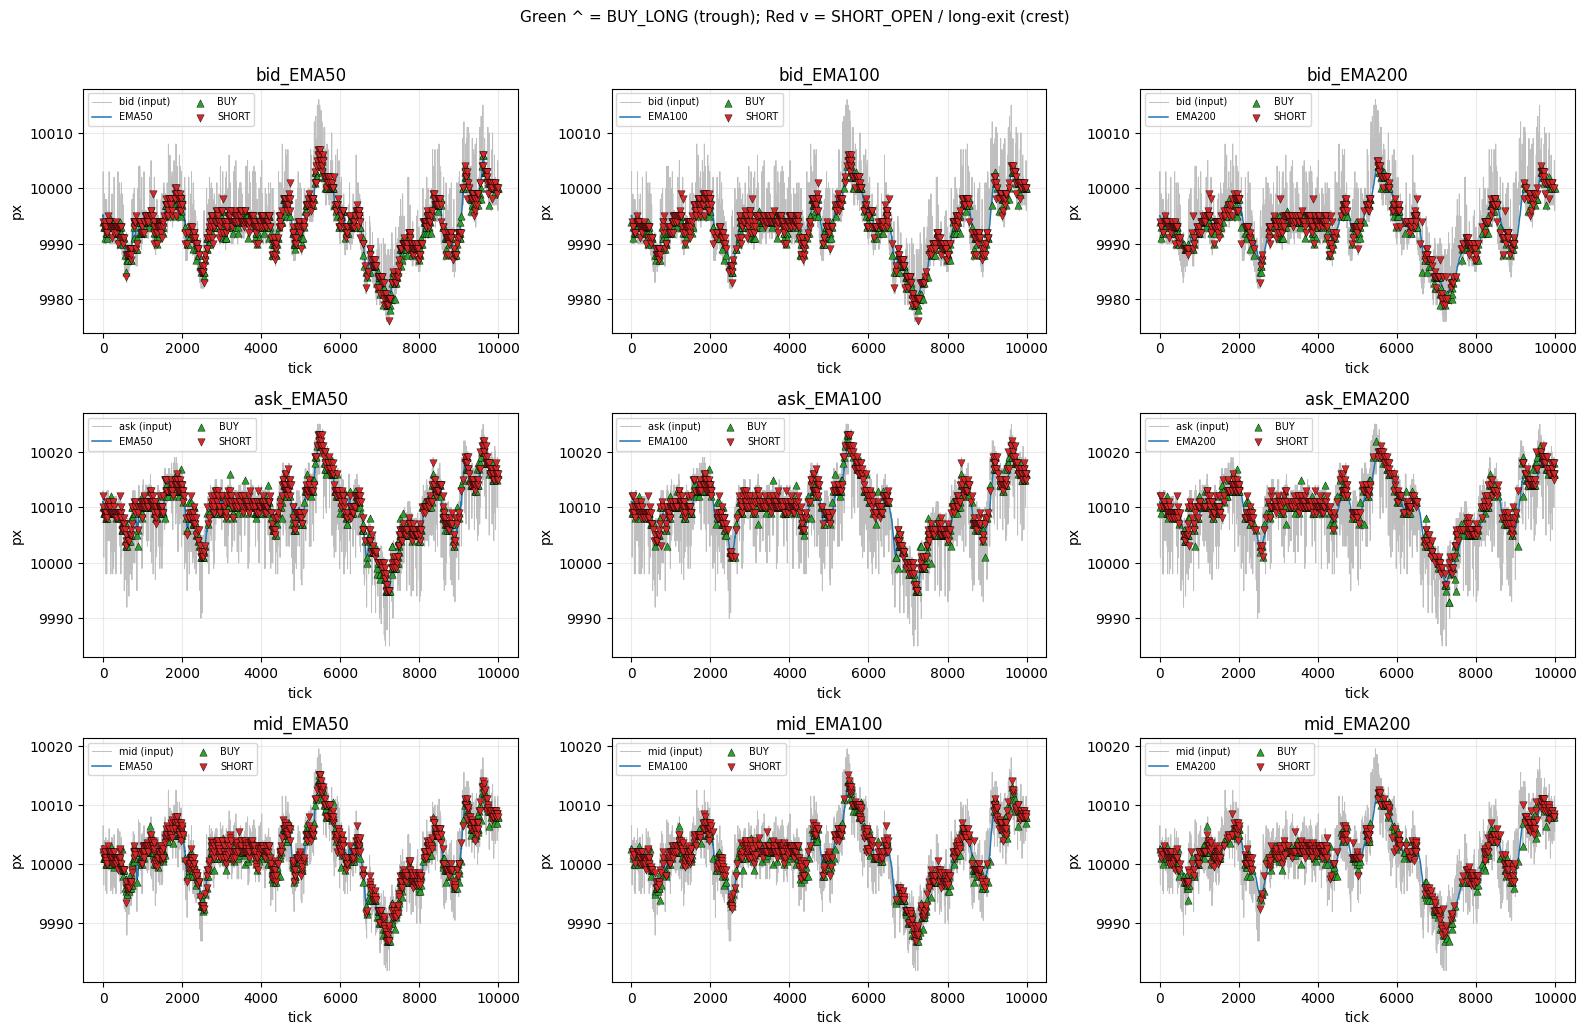

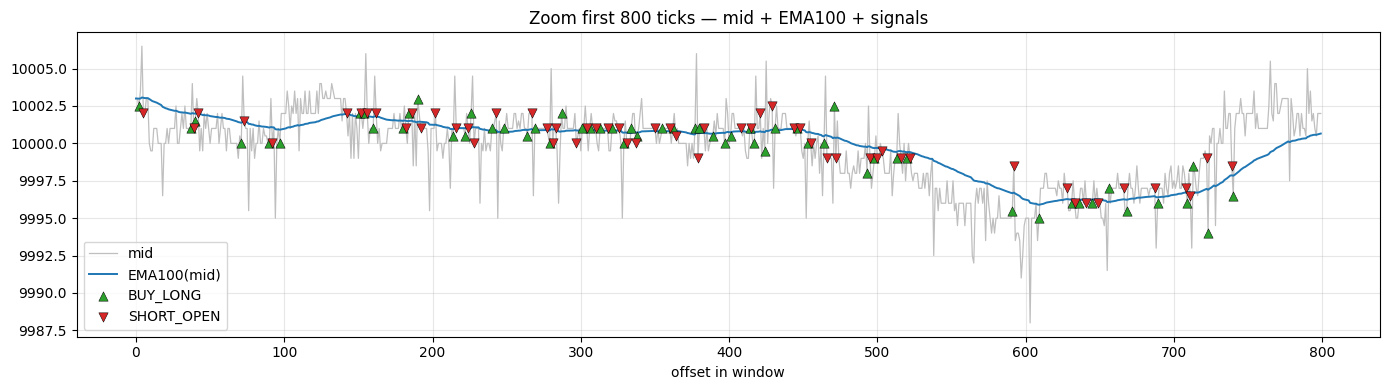

Note: SHORT_OPEN marks crests (sell bid). Long-only FIFO PnL uses those crests as long exits. Dedicated short inventory / cover logic is not run in this cell.


In [44]:
# --- Multi-scenario signal sweep: BUY (long @ ask) vs SHORT (open @ bid) from EMA troughs / crests ---
# Trough: d(EMA) crosses up through 0 and dd>0 -> BUY_LONG (pay ask). Crest: d crosses down, dd<0 -> SHORT_OPEN (hit bid).
# Long round-trip PnL: same as before (accumulate at ask, liquidate stack at bid on crest). Short leg PnL not simulated here.
from collections import deque

bid_price_1 = os_df1["bid_price_1"].ffill().to_numpy(dtype=float)
ask_price_1 = os_df1["ask_price_1"].ffill().to_numpy(dtype=float)
mid_price = (bid_price_1 + ask_price_1) / 2.0

SPANS = (50, 100, 200)
SOURCE_SPECS = (
    ("bid", bid_price_1),
    ("ask", ask_price_1),
    ("mid", mid_price),
)


def crossing_long_short(d, dd):
    n = len(d)
    long_entry = np.zeros(n, dtype=bool)
    short_entry = np.zeros(n, dtype=bool)
    for i in range(1, n):
        if d[i - 1] * d[i] >= 0:
            continue
        if d[i - 1] < 0 < d[i] and dd[i] > 0:
            long_entry[i] = True
        elif d[i - 1] > 0 > d[i] and dd[i] < 0:
            short_entry[i] = True
    return long_entry, short_entry


def deriv_chain(y, span):
    ema = pd.Series(y, dtype=float).ewm(span=span, adjust=False).mean().to_numpy()
    d1 = np.gradient(ema)
    d2 = np.gradient(d1)
    return {"ema": ema, "d1": d1, "dd": d2}


def paper_trade_long_only(long_enter, exit_on_crest, bids, asks, name):
    q = deque()
    realized = 0.0
    n_trades_buy = 0
    n_trades_sell = 0
    for i in range(len(bids)):
        if exit_on_crest[i]:
            while q:
                realized += bids[i] - q.popleft()
                n_trades_sell += 1
        if long_enter[i]:
            q.append(asks[i])
            n_trades_buy += 1
    unrealized = 0.0
    if q:
        last_bid = bids[-1]
        unrealized = sum(last_bid - ap for ap in q)
    return {
        "name": name,
        "realized_pnl": realized,
        "unrealized_if_flat_at_last_bid": unrealized,
        "total_pnl_realized_plus_unrealized": realized + unrealized,
        "open_lots": len(q),
        "buy_signals_taken": n_trades_buy,
        "units_sold": n_trades_sell,
    }


def signal_points_table(scenario, long_mask, short_mask, bids, asks):
    rows = []
    for i in np.where(long_mask)[0]:
        rows.append(
            {
                "scenario": scenario,
                "tick": int(i),
                "action": "BUY_LONG",
                "bid": float(bids[i]),
                "ask": float(asks[i]),
                "exec_px": float(asks[i]),
            }
        )
    for i in np.where(short_mask)[0]:
        rows.append(
            {
                "scenario": scenario,
                "tick": int(i),
                "action": "SHORT_OPEN",
                "bid": float(bids[i]),
                "ask": float(asks[i]),
                "exec_px": float(bids[i]),
            }
        )
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return df.sort_values(["tick", "action"]).reset_index(drop=True)


scenario_rows = []
all_signal_frames = []

for src_name, y in SOURCE_SPECS:
    for span in SPANS:
        ch = deriv_chain(y, span)
        long_e, short_e = crossing_long_short(ch["d1"], ch["dd"])
        name = f"{src_name}_EMA{span}"
        pnl = paper_trade_long_only(long_e, short_e, bid_price_1, ask_price_1, name)
        scenario_rows.append(
            {
                **pnl,
                "source": src_name,
                "span": span,
                "n_buy_long": int(long_e.sum()),
                "n_short_open": int(short_e.sum()),
            }
        )
        tbl = signal_points_table(name, long_e, short_e, bid_price_1, ask_price_1)
        if not tbl.empty:
            all_signal_frames.append(tbl)

scenario_summary = pd.DataFrame(scenario_rows)
try:
    display(scenario_summary.sort_values("total_pnl_realized_plus_unrealized"))
except NameError:
    print(scenario_summary.sort_values("total_pnl_realized_plus_unrealized").to_string())

if all_signal_frames:
    signal_atlas = pd.concat(all_signal_frames, ignore_index=True)
    try:
        display(signal_atlas.head(50))
    except NameError:
        print(signal_atlas.head(50).to_string())
else:
    signal_atlas = pd.DataFrame()

print("\n=== Sample BUY / SHORT ticks (first 3 each) per scenario ===\n")
for name in scenario_summary["name"]:
    if signal_atlas.empty:
        break
    sub = signal_atlas[signal_atlas["scenario"] == name]
    b = sub[sub["action"] == "BUY_LONG"].head(3)
    s = sub[sub["action"] == "SHORT_OPEN"].head(3)
    if len(b) == 0 and len(s) == 0:
        continue
    print(name)
    if len(b):
        print("  BUY_LONG:", b[["tick", "exec_px"]].to_string(index=False))
    if len(s):
        print("  SHORT_OPEN:", s[["tick", "exec_px"]].to_string(index=False))
    print()

# --- Visibility: 3x3 grid of source series + EMA + markers ---
n_sc = len(SOURCE_SPECS) * len(SPANS)
ncols = 3
nrows = int(np.ceil(n_sc / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows), squeeze=False)
axes_flat = axes.ravel()
idx = 0
for src_name, y in SOURCE_SPECS:
    for span in SPANS:
        ax = axes_flat[idx]
        ch = deriv_chain(y, span)
        long_e, short_e = crossing_long_short(ch["d1"], ch["dd"])
        xp = np.arange(len(y))
        ax.plot(xp, y, color="0.75", lw=0.7, label=f"{src_name} (input)")
        ax.plot(xp, ch["ema"], color="C0", lw=1.1, label=f"EMA{span}")
        li = np.where(long_e)[0]
        si = np.where(short_e)[0]
        if len(li):
            ax.scatter(li, y[li], c="tab:green", s=28, zorder=6, marker="^", edgecolors="k", linewidths=0.3, label="BUY")
        if len(si):
            ax.scatter(si, y[si], c="tab:red", s=28, zorder=6, marker="v", edgecolors="k", linewidths=0.3, label="SHORT")
        ax.set_title(f"{src_name}_EMA{span}")
        ax.legend(fontsize=7, loc="best", ncol=2)
        ax.grid(True, alpha=0.25)
        ax.set_xlabel("tick")
        ax.set_ylabel("px")
        idx += 1
for j in range(idx, len(axes_flat)):
    axes_flat[j].set_visible(False)
fig.suptitle("Green ^ = BUY_LONG (trough); Red v = SHORT_OPEN / long-exit (crest)", y=1.01, fontsize=11)
plt.tight_layout()
plt.show()

# --- Zoom visibility: mid EMA100 only ---
Z = 800
z = slice(0, min(Z, len(mid_price)))
xx = np.arange(len(mid_price[z]))
chz = deriv_chain(mid_price[z], 100)
lez, sez = crossing_long_short(chz["d1"], chz["dd"])
fig2, axz = plt.subplots(figsize=(14, 4))
axz.plot(xx, mid_price[z], color="0.75", lw=0.9, label="mid")
axz.plot(xx, chz["ema"], color="C0", lw=1.4, label="EMA100(mid)")
axz.scatter(np.where(lez)[0], mid_price[z][lez], c="tab:green", s=45, zorder=6, marker="^", edgecolors="k", linewidths=0.35, label="BUY_LONG")
axz.scatter(np.where(sez)[0], mid_price[z][sez], c="tab:red", s=45, zorder=6, marker="v", edgecolors="k", linewidths=0.35, label="SHORT_OPEN")
axz.set_title(f"Zoom first {len(xx)} ticks — mid + EMA100 + signals")
axz.set_xlabel("offset in window")
axz.legend(loc="best")
axz.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Back-compat names for any cells below that expect ema100 on bid only:
EMA_SPAN = 100
ema_bid = deriv_chain(bid_price_1, EMA_SPAN)["ema"]
ema_ask = deriv_chain(ask_price_1, EMA_SPAN)["ema"]
d_bid_price_1 = np.gradient(ema_bid)
d_ask_price_1 = np.gradient(ema_ask)
dd_bid_price_1 = np.gradient(d_bid_price_1)
dd_ask_price_1 = np.gradient(d_ask_price_1)

print(
    "Note: SHORT_OPEN marks crests (sell bid). Long-only FIFO PnL uses those crests as long exits. "
    "Dedicated short inventory / cover logic is not run in this cell."
)


<Axes: >

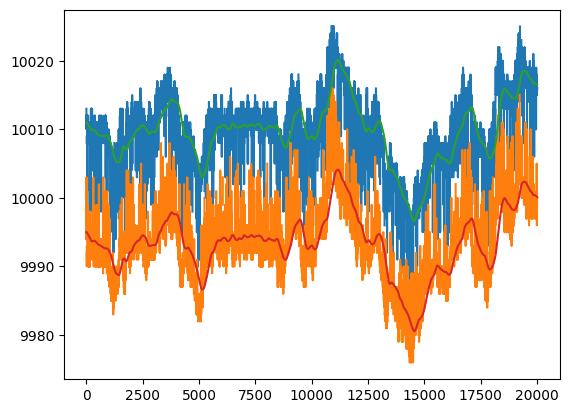

In [56]:
ask_prices = os_df1['ask_price_1']
bid_prices = os_df1['bid_price_1']

ask_prices.plot()
bid_prices.plot()

ema_ask_prices = ask_prices.ewm(span=50, adjust=False).mean()
ema_bid_prices = bid_prices.ewm(span=50, adjust=False).mean()

eema_ask_prices = ema_ask_prices.ewm(span=200, adjust=False).mean()
eema_bid_prices = ema_bid_prices.ewm(span=200, adjust=False).mean()

eema_ask_prices.plot()
eema_bid_prices.plot()

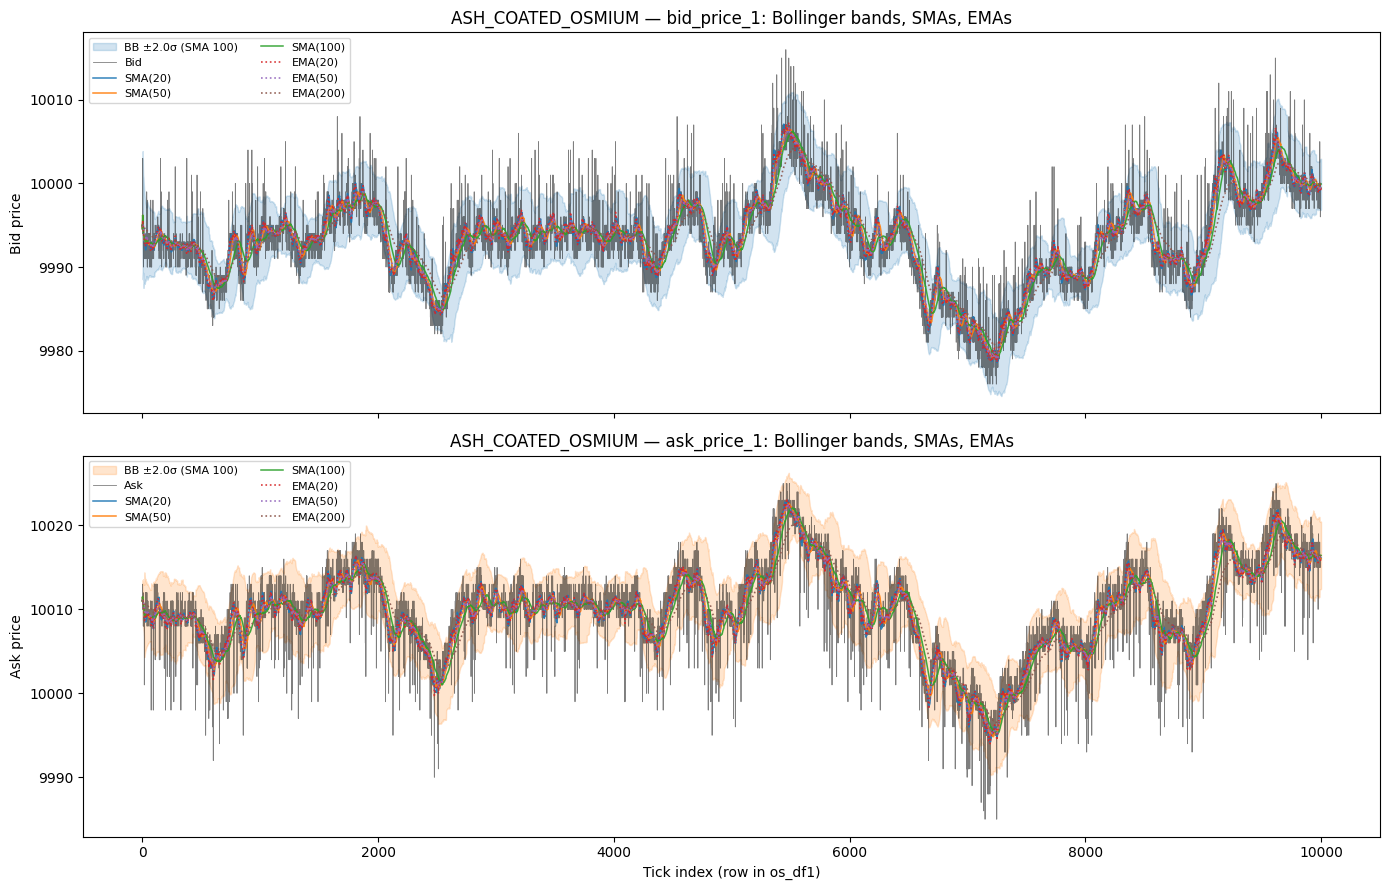

BB backtest (os_df1): final realized PnL ≈ -21,212.00 | ticks with equity trace: 9900


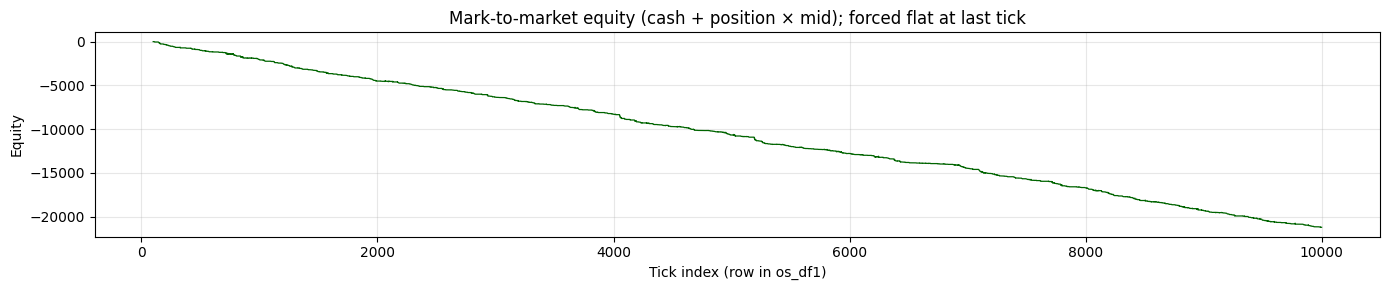

In [70]:
# Bollinger bands on ASH_COATED_OSMIUM best bid / best ask (day 0, os_df1)
bb_window = 100
num_std = 2.0
sma_windows = [20, 50, 100]
ema_spans = [20, 50, 200]

bid = os_df1["bid_price_1"].ffill().astype(float)
ask = os_df1["ask_price_1"].ffill().astype(float)

bid_mid = bid.rolling(bb_window, min_periods=1).mean()
bid_std = bid.rolling(bb_window, min_periods=1).std()
bid_upper = bid_mid + num_std * bid_std
bid_lower = bid_mid - num_std * bid_std

ask_mid = ask.rolling(bb_window, min_periods=1).mean()
ask_std = ask.rolling(bb_window, min_periods=1).std()
ask_upper = ask_mid + num_std * ask_std
ask_lower = ask_mid - num_std * ask_std

x = np.arange(len(bid))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].fill_between(x, bid_lower, bid_upper, color="C0", alpha=0.2, label=f"BB ±{num_std}σ (SMA {bb_window})")
axes[0].plot(x, bid, color="black", lw=0.6, alpha=0.5, label="Bid")
for w in sma_windows:
    axes[0].plot(
        x,
        bid.rolling(w, min_periods=1).mean(),
        lw=1.1,
        alpha=0.9,
        label=f"SMA({w})",
    )
for span in ema_spans:
    axes[0].plot(
        x,
        bid.ewm(span=span, adjust=False).mean(),
        ls=":",
        lw=1.2,
        alpha=0.9,
        label=f"EMA({span})",
    )
axes[0].set_ylabel("Bid price")
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
axes[0].set_title("ASH_COATED_OSMIUM — bid_price_1: Bollinger bands, SMAs, EMAs")

axes[1].fill_between(x, ask_lower, ask_upper, color="C1", alpha=0.2, label=f"BB ±{num_std}σ (SMA {bb_window})")
axes[1].plot(x, ask, color="black", lw=0.6, alpha=0.5, label="Ask")
for w in sma_windows:
    axes[1].plot(
        x,
        ask.rolling(w, min_periods=1).mean(),
        lw=1.1,
        alpha=0.9,
        label=f"SMA({w})",
    )
for span in ema_spans:
    axes[1].plot(
        x,
        ask.ewm(span=span, adjust=False).mean(),
        ls=":",
        lw=1.2,
        alpha=0.9,
        label=f"EMA({span})",
    )
axes[1].set_ylabel("Ask price")
axes[1].set_xlabel("Tick index (row in os_df1)")
axes[1].legend(loc="upper left", fontsize=8, ncol=2)
axes[1].set_title("ASH_COATED_OSMIUM — ask_price_1: Bollinger bands, SMAs, EMAs")

plt.tight_layout()
plt.show()

# --- small backtest: breakouts add; "in zone" chips position toward 0 using book size ---
# Breakout long:  ask < lower BB  -> buy @ ask (room up to net +POS_LIM)
# Breakout short: bid > upper BB -> sell @ bid (room down to net -POS_LIM)
# In zone (neither breakout): sell longs into bid_v, cover shorts with ask_v each tick

POS_LIM = 80

ask_v = os_df1["ask_volume_1"].fillna(0).to_numpy(dtype=float)
bid_v = os_df1["bid_volume_1"].fillna(0).to_numpy(dtype=float)
bid_arr = bid.to_numpy()
ask_arr = ask.to_numpy()
al = ask_lower.to_numpy()
bu = bid_upper.to_numpy()

position = 0.0
cash = 0.0
n = len(bid_arr)
equity = np.full(n, np.nan)

for i in range(bb_window, n):
    b, a = bid_arr[i], ask_arr[i]
    mid = 0.5 * (b + a)

    if a < al[i]:
        room = max(0, int(POS_LIM - position))
        q = min(int(ask_v[i]), room)
        if q > 0:
            cash -= q * a
            position += q
    elif b > bu[i]:
        room = max(0, int(POS_LIM + position))
        q = min(int(bid_v[i]), room)
        if q > 0:
            cash += q * b
            position -= q
    else:
        if position > 0:
            q = min(int(bid_v[i]), int(position))
            if q > 0:
                cash += q * b
                position -= q
        elif position < 0:
            q = min(int(ask_v[i]), int(-position))
            if q > 0:
                cash -= q * a
                position += q

    equity[i] = cash + position * mid

if position > 0:
    cash += position * bid_arr[-1]
    position = 0.0
elif position < 0:
    cash -= (-position) * ask_arr[-1]
    position = 0.0

equity[-1] = cash
final_pnl = cash
valid = equity[np.isfinite(equity)]
print(
    "BB backtest (os_df1):",
    f"final realized PnL ≈ {final_pnl:,.2f}",
    f"| max |net| = {POS_LIM}",
    f"| ticks with equity trace: {len(valid)}",
)

fig2, ax_e = plt.subplots(figsize=(14, 3))
ax_e.plot(x, equity, lw=0.9, color="darkgreen")
ax_e.set_title("Equity: breakout adds (± cap); in-zone settlement; flat EOD")
ax_e.set_xlabel("Tick index (row in os_df1)")
ax_e.set_ylabel("Equity")
ax_e.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [63]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import argrelextrema

def detect_trends_and_reversals(
    df: pd.DataFrame,
    price_col: str = 'ask_price_1',
    window: int = 20,          # Regression window
    vol_window: int = 20,      # Volatility window (for adaptive thresholds)
    min_prominence: float = 1.5, # Min move in units of recent volatility
    confirmation_bars: int = 2,
    sideways_threshold: float = 0.3  # Fraction of volatility for "sideways"
):
    """
    Detects trends, reversal points, and regime changes with uncertainty quantification.
    
    Returns DataFrame with:
      - trend: 'up', 'down', 'sideways'
      - reversal_signal: 'bullish', 'bearish', NaN
      - confidence: 0-1 (higher = more reliable)
      - regime_start: Boolean (start of new trend regime)
    """
    df = df.copy()
    price = df[price_col]
    
    # ===== STEP 1: ADAPTIVE VOLATILITY NORMALIZATION =====
    # Critical: Thresholds scale with asset's recent volatility (ATR proxy)
    log_returns = np.log(price / price.shift(1))
    volatility = log_returns.rolling(vol_window).std().bfill()
    min_move = min_prominence * volatility * price  # Adaptive significance threshold
    
    # ===== STEP 2: ROLLING REGRESSION SLOPE (TREND DIRECTION) =====
    def calc_slope(y):
        if len(y) < 3: 
            return np.nan
        x = np.arange(len(y))
        slope, _, _, _, _ = stats.linregress(x, y)
        return slope
    
    slope = price.rolling(window).apply(calc_slope, raw=True)
    norm_slope = slope / (price * volatility)  # Volatility-normalized slope
    
    # ===== STEP 3: TREND CLASSIFICATION WITH UNCERTAINTY BANDS =====
    sideways_band = sideways_threshold
    df['trend'] = np.where(
        norm_slope > sideways_band, 'up',
        np.where(norm_slope < -sideways_band, 'down', 'sideways')
    )
    
    # Confidence: Stronger slope + lower noise = higher confidence
    slope_strength = np.abs(norm_slope) / sideways_band
    noise_ratio = volatility.rolling(10).mean() / volatility.rolling(50).mean()
    df['confidence'] = np.clip(slope_strength * (1 - noise_ratio), 0.1, 1.0)
    
    # ===== STEP 4: REVERSAL POINT DETECTION (PEAKS/VALLEYS + CONFIRMATION) =====
    # Find significant local extrema using adaptive prominence
    order = max(3, window // 5)
    
    # Local maxima (potential resistance peaks)
    peaks = argrelextrema(price.values, np.greater, order=order)[0]
    valid_peaks = [i for i in peaks if 
                   i >= window and 
                   (price.iloc[i] - price.iloc[i-window:i].min()) > min_move.iloc[i]]
    
    # Local minima (potential support troughs)
    troughs = argrelextrema(price.values, np.less, order=order)[0]
    valid_troughs = [i for i in troughs if 
                     i >= window and 
                     (price.iloc[i-window:i].max() - price.iloc[i]) > min_move.iloc[i]]
    
    # Initialize signals
    df['reversal_signal'] = np.nan
    df['regime_start'] = False
    
    # Mark confirmed reversals
    for idx in valid_peaks:
        if idx + confirmation_bars < len(df):
            # Bearish reversal: peak followed by sustained down move
            if (df['trend'].iloc[idx+1:idx+confirmation_bars+1] == 'down').all():
                df.loc[df.index[idx], 'reversal_signal'] = 'bearish'
                df.loc[df.index[idx+confirmation_bars], 'regime_start'] = True
    
    for idx in valid_troughs:
        if idx + confirmation_bars < len(df):
            # Bullish reversal: trough followed by sustained up move
            if (df['trend'].iloc[idx+1:idx+confirmation_bars+1] == 'up').all():
                df.loc[df.index[idx], 'reversal_signal'] = 'bullish'
                df.loc[df.index[idx+confirmation_bars], 'regime_start'] = True
    
    # ===== STEP 5: UNCERTAINTY FLAGS (CRITICAL FOR "NO ERROR" CLAIM) =====
    df['low_confidence'] = df['confidence'] < 0.4
    df['high_volatility'] = volatility > volatility.rolling(50).mean() * 1.5
    df['ambiguous_regime'] = (
        (df['trend'] == 'sideways') & 
        (df['confidence'] < 0.5) &
        (df['high_volatility'])
    )
    
    return df[['trend', 'reversal_signal', 'regime_start', 'confidence', 
               'low_confidence', 'ambiguous_regime']]


In [64]:
trend_df = detect_trends_and_reversals(os_df1)

In [67]:
trend_df

,trend,reversal_signal,regime_start,confidence,low_confidence,ambiguous_regime
0,sideways,NaN,False,NaN,False,False
3,sideways,NaN,False,NaN,False,False
5,sideways,NaN,False,NaN,False,False
6,sideways,NaN,False,NaN,False,False
8,sideways,NaN,False,NaN,False,False
...,...,...,...,...,...,...
19990,sideways,NaN,False,0.1,True,False
19993,sideways,NaN,False,0.1,True,False
19994,sideways,NaN,False,NaN,False,False
19997,sideways,NaN,False,NaN,False,False


In [58]:
d_ema_bid_prices = np.gradient(eema_bid_prices)
idx_bid_prices = deriv_zero_indices(d_ema_bid_prices)

idx_bid_prices

array([   2,    5,   29, ..., 9984, 9989, 9994], shape=(1559,))

<Axes: >

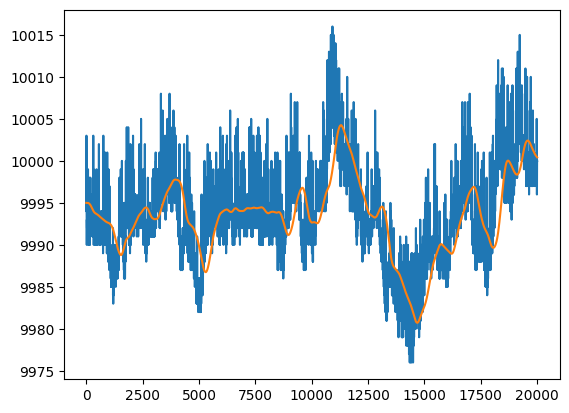

In [48]:
ema50 = ema50.ewm(span=100, adjust=False).mean()
price.plot()
ema50.plot()

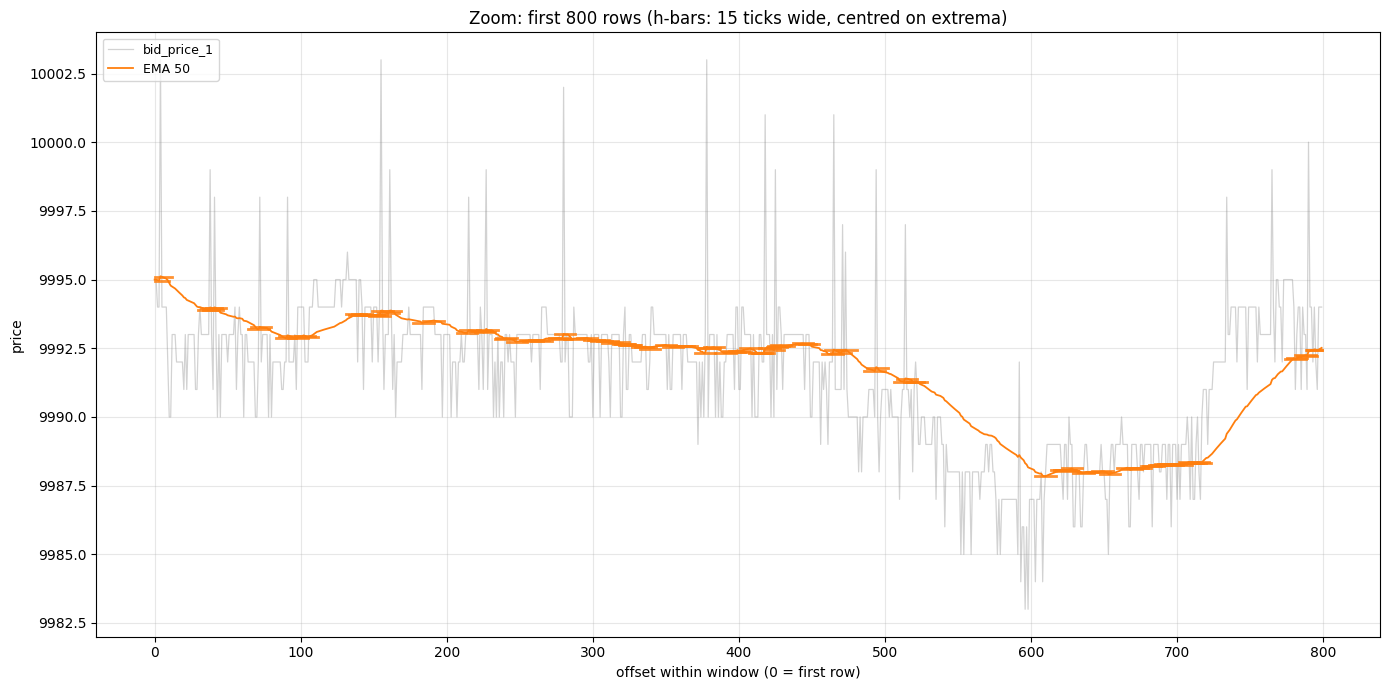

In [42]:
ema20 = price.ewm(span=20, adjust=False).mean()
ema50 = price.ewm(span=100, adjust=False).mean()
ema100 = price.ewm(span=200, adjust=False).mean()

fig, axes = plt.subplots(1, 1, figsize=(14, 7), sharex=False)
N = 800
z = slice(0, min(N, len(price)))
n_z = len(price.iloc[z])
xx = np.arange(n_z)
ax1 = axes
ax1.plot(xx, price.iloc[z].to_numpy(), alpha=0.35, label="bid_price_1", color="gray", linewidth=0.9)
#ax1.plot(xx, ema20.iloc[z].to_numpy(), label="EMA 20", linewidth=1.3, color="C0")
ax1.plot(xx, ema50.iloc[z].to_numpy(), label="EMA 50", linewidth=1.3, color="C1")
#ax1.plot(xx, ema100.iloc[z].to_numpy(), label="EMA 100", linewidth=1.3, color="C2")
#sketch_deriv_zero_hlines(ax1, ema20.iloc[z], "C0")
sketch_deriv_zero_hlines(ax1, ema50.iloc[z], "C1")
#sketch_deriv_zero_hlines(ax1, ema100.iloc[z], "C2")
ax1.set_title(f"Zoom: first {n_z} rows (h-bars: {SEG_LEN} ticks wide, centred on extrema)")
ax1.set_xlabel("offset within window (0 = first row)")
ax1.set_ylabel("price")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
len(zero_indices100)

1425

In [18]:
### Statergy for Pepper will be to hold and sell only ###
os_df1

,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,0,0,ASH_COATED_OSMIUM,9995.0,13.0,9992.0,21.0,NaN,NaN,10011.0,13.0,10013.0,21.0,NaN,NaN,10003.0,0.0
3,0,100,ASH_COATED_OSMIUM,9995.0,15.0,9992.0,26.0,NaN,NaN,10011.0,15.0,10013.0,26.0,NaN,NaN,10003.0,0.0
5,0,200,ASH_COATED_OSMIUM,9994.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9994.0,0.0
6,0,300,ASH_COATED_OSMIUM,9994.0,12.0,9992.0,27.0,NaN,NaN,10013.0,27.0,NaN,NaN,NaN,NaN,10003.5,0.0
8,0,400,ASH_COATED_OSMIUM,10003.0,8.0,9994.0,12.0,9991.0,25.0,10010.0,12.0,10012.0,25.0,NaN,NaN,10006.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19990,0,999500,ASH_COATED_OSMIUM,10000.0,11.0,NaN,NaN,NaN,NaN,10016.0,11.0,NaN,NaN,NaN,NaN,10008.0,0.0
19993,0,999600,ASH_COATED_OSMIUM,10000.0,13.0,9997.0,30.0,NaN,NaN,10016.0,13.0,NaN,NaN,NaN,NaN,10008.0,0.0
19994,0,999700,ASH_COATED_OSMIUM,10000.0,13.0,9997.0,28.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.0,0.0
19997,0,999800,ASH_COATED_OSMIUM,10000.0,10.0,9997.0,27.0,NaN,NaN,10016.0,10.0,10018.0,27.0,NaN,NaN,10008.0,0.0


In [ ]:
### Introducing two terminologies the number of long points before the current point means if I am selling it today how many points exist in past where
### the product could have been bought (in short num(prev_ask_prices<current_bid_price))
### The num of short points is reverse the number of bid points above the current ask price where the product could have been shorted.
from tqdm import tqdm
os_df1['num_long_points'] = 0
os_df1['num_short_points'] = 0

for idx,row in tqdm(os_df1[1:].iterrows()):
    bid_price_1 = row['bid_price_1']
    ask_price_1 = row['ask_price_1']
    timestamp = row['timestamp']
    
    if bid_price_1 is not None:
        sub_df = os_df1[(os_df1['timestamp']<timestamp) & (os_df1['ask_price_1']<bid_price_1)]

        os_df1.loc[idx, 'num_long_points'] = len(sub_df)

    if ask_price_1 is not None:
        sub_df = os_df1[(os_df1['timestamp']<timestamp) & (os_df1['bid_price_1']>ask_price_1)]
        os_df1.loc[idx, 'num_short_points'] = len(sub_df)
    

9999it [00:06, 1648.51it/s]


<Axes: >

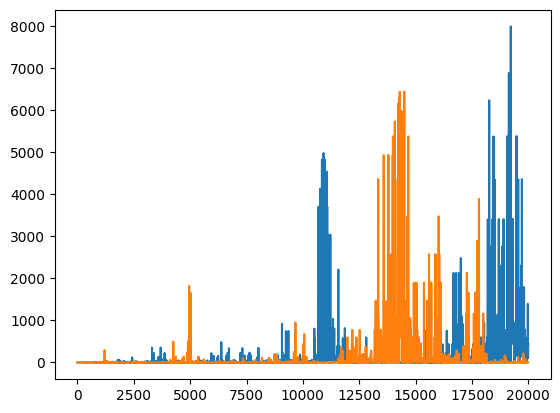

In [24]:
os_df1['num_long_points'].plot()
os_df1['num_short_points'].plot()

In [ ]:
os_df1['position'] = None

for idx,row in tqdm(os_df1[1:].iterrows()):
    bid_price_1 = row['bid_price_1']
    ask_price_1 = row['ask_price_1']
    timestamp = row['timestamp']

    
    
    


**pandas 2.0+:** `fillna(method='bfill'|'ffill')` was removed. Use **`.bfill()`** / **`.ffill()`** on the Series instead (e.g. after `.rolling(...).std()`).

In [ ]:
# In detect_trends_and_reversals (Cell 59), replace deprecated fillna(method=...):
# BEFORE: volatility = log_returns.rolling(vol_window).std().fillna(method='bfill')
# AFTER:
# volatility = log_returns.rolling(vol_window).std().bfill()
# Any .fillna(method='ffill') -> .ffill()